In [47]:
import glob
import os
import time
import warnings
import sklearn
import shap
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import enlighten
import matplotlib.pyplot as plt
import io


from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from xgboost import XGBClassifier

from ipywidgets import IntProgress
from IPython.display import display

In [37]:
def features_ml_models(X, y, random_seed, variables, axes = None, sp= None, factor = None,i =None, j=None,  is_binary=False, is_balanced = False, plot = False):
    """Train and evaluate ML models on feature data, extracting both metrics and confusion matrices.

    Args:
        X (pd.DataFrame): Feature matrix
        y (pd.Series): Target variable (either binary or multiclass)
        random_seed (int): Random seed for train/test split
        is_binary (bool): Whether this is binary classification

    Returns:
        tuple: (metrics_df, confusion_df, SHAP_values) with model performance metrics and confusion matrix data
    """
    X = X.reset_index(drop=True)
    
    # Encode target variables
    target_encoder = LabelEncoder()
    y_encoded = target_encoder.fit_transform(y)

    # Special handling for binary classification to ensure proper encoding
    if is_binary and len(target_encoder.classes_) == 2:
        # Ensure "Active" is encoded as 1 and "Inactive" as 0 if these are the class names
        if (
            "Active" in target_encoder.classes_
            and "Inactive" in target_encoder.classes_
        ):
            if target_encoder.transform(["Active"])[0] != 1:
                target_encoder.classes_ = target_encoder.classes_[::-1]
                y_encoded = target_encoder.transform(y)

        # Train and test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, stratify=y_encoded, test_size=0.25, random_state=random_seed
    )

    # Define the models
    models = {
       # "RF": RandomForestClassifier(n_estimators=100, random_state=42),
        "XGB": XGBClassifier(random_state=random_seed),
        #"SVC": SVC(kernel="rbf", cache_size=1000, probability=True, random_state=42),
    }

    # Create lists to store the results and confusion matrix data
    metrics_results = []
    confusion_data = []

    # Iterate over the models
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for model_name, model in models.items():
            start_time = time.time()


            # Fit the model with 
            
                        # Fit the model with
            if is_balanced == False:  
                model.fit(X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train) )
            
            else:
                model.fit(X_train, y_train )

            # Predictions
            y_pred = model.predict(X_test)
            y_pred_proba = model.predict_proba(X_test)

            # Calculate accuracy
            accuracy = model.score(X_test, y_test)

            # Calculate ROC AUC - handle binary and multiclass differently
            if is_binary:
                roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])
            else:
                roc_auc = roc_auc_score(
                    y_test, y_pred_proba, multi_class="ovr", average="weighted"
                )

            # Calculate balanced accuracy
            balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

            # Calculate F1 score
            f1 = f1_score(y_test, y_pred, average="weighted")

            # Calculate precision
            precision = precision_score(
                y_test, y_pred, average="weighted", zero_division=0
            )

            # Calculate recall
            recall = recall_score(y_test, y_pred, average="weighted")

            # SHAP values 

            if model_name == "XGB":
                #print("XGB")
                #explainer = shap.TreeExplainer(model)
                explainer = shap.TreeExplainer(model, model_output= "raw" )
                explanation = explainer(X_train)

                shap_values = explanation.values
                # make sure the SHAP values add up to marginal predictions
                #np.abs(shap_values.sum(axis=1) + explanation.base_values - y_test).max()
                
                #new_index = [ix for ix_test_fold in ix_test for ix in ix_test_fold]
                if explanation is not None: # Ensure you only add valid explanations
                    explanations_list.append(explanation)
                    titles_list.append(f"{sp} - {factor}")
                    
                if plot == True :
                    #
                    shap.plots.beeswarm(explanation, plot_size =None, ax=axes[i * 2 + j]) #, feature_names=X.columns)
                    #axes[i * 2 + j].set_title(f"{sp} - {factor}")
                    #shap.plots.bar(explanation)
                    #shap.plots.scatter(shap_values[:, "Relationship"], color=shap_values)
                
                #shap_values_df = pd.DataFrame(shap_values,  columns=X.columns)
                vals= np.abs(shap_values).mean(0)

                feature_importance = pd.DataFrame(list(zip(X_train.columns, vals)))
                feature_importance_df = feature_importance.T


            train_time = time.time() - start_time

            # Append the metrics to the results list


            # Get and process confusion matrix
            cm = confusion_matrix(y_test, y_pred)

            # Convert confusion matrix to DataFrame format
            for i in range(len(cm)):
                for j in range(len(cm)):
                    confusion_data.append(
                        {
                            "model": model_name,
                            "actual_label": i,
                            "predicted_label": j,
                            "count": cm[i][j],
                        }
                    )

            #print(f"{model_name} Done")

    # Convert results to DataFrames
    confusion_df = pd.DataFrame(confusion_data)

    # Map the encoded labels back to original classes if possible
    original_classes = target_encoder.classes_
    if len(confusion_df) > 0:
        confusion_df["actual_label"] = confusion_df["actual_label"].apply(
            lambda x: original_classes[x] if x < len(original_classes) else x
        )
        confusion_df["predicted_label"] = confusion_df["predicted_label"].apply(
            lambda x: original_classes[x] if x < len(original_classes) else x
        )

        metrics_results.append(
        {
            "model": model_name,
            "roc_auc": roc_auc,
            "accuracy": accuracy,
            "balanced_acc": balanced_accuracy,
            "f1_score": f1,
            "precision": precision,
            "recall": recall,
            "time": train_time,
            "TP" : confusion_df.loc[3, "count"],
            "TN" : confusion_df.loc[0, "count"],
            "FP" : confusion_df.loc[1, "count"],
            "FN" :  confusion_df.loc[2, "count"]
        }

    )
        metrics_df = pd.DataFrame(metrics_results)
        
    return metrics_df, feature_importance_df


In [12]:
def features_ml_models(X, y, random_seed, variables, is_binary=False, is_balanced = False, plot = False):
    """Train and evaluate ML models on feature data, extracting both metrics and confusion matrices.

    Args:
        X (pd.DataFrame): Feature matrix
        y (pd.Series): Target variable (either binary or multiclass)
        random_seed (int): Random seed for train/test split
        is_binary (bool): Whether this is binary classification

    Returns:
        tuple: (metrics_df, confusion_df, SHAP_values) with model performance metrics and confusion matrix data
    """
    X = X.reset_index(drop=True)
    
    # Encode target variables
    target_encoder = LabelEncoder()
    y_encoded = target_encoder.fit_transform(y)

    # Special handling for binary classification to ensure proper encoding
    if is_binary and len(target_encoder.classes_) == 2:
        # Ensure "Active" is encoded as 1 and "Inactive" as 0 if these are the class names
        if (
            "Active" in target_encoder.classes_
            and "Inactive" in target_encoder.classes_
        ):
            if target_encoder.transform(["Active"])[0] != 1:
                target_encoder.classes_ = target_encoder.classes_[::-1]
                y_encoded = target_encoder.transform(y)

        # Train and test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, stratify=y_encoded, test_size=0.25, random_state=random_seed
    )

    # Define the models
    models = {
        "RF": RandomForestClassifier(n_estimators=100, random_state=random_seed),
    #    "XGB": XGBClassifier(random_state=random_seed),
        #"SVC": SVC(kernel="rbf", cache_size=1000, probability=True, random_state=42),
    }

    # Create lists to store the results and confusion matrix data
    metrics_results = []
    confusion_data = []

    # Iterate over the models
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for model_name, model in models.items():
            start_time = time.time()


            # Fit the model with 
            
                        # Fit the model with
            if is_balanced == False:  
                model.fit(X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train) )
            
            else:
                model.fit(X_train, y_train )

            # Predictions
            y_pred = model.predict(X_test)
            y_pred_proba = model.predict_proba(X_test)

            # Calculate accuracy
            accuracy = model.score(X_test, y_test)

            # Calculate ROC AUC - handle binary and multiclass differently
            if is_binary:
                roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])
            else:
                roc_auc = roc_auc_score(
                    y_test, y_pred_proba, multi_class="ovr", average="weighted"
                )

            # Calculate balanced accuracy
            balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

            # Calculate F1 score
            f1 = f1_score(y_test, y_pred, average="weighted")

            # Calculate precision
            precision = precision_score(
                y_test, y_pred, average="weighted", zero_division=0
            )

            # Calculate recall
            recall = recall_score(y_test, y_pred, average="weighted")

            # SHAP values 

            #if model_name == "XGB":
                #print("XGB")
            explainer = shap.TreeExplainer(model, model_output= "raw" )
            explanation = explainer(X)
            shap_values = explanation.values
            #shap_values = explainer.shap_values(X) ## try modeks output to raw  or change to Explainer 


            print(f"shapeof shap_values {shap_values.shape}")
            # make sure the SHAP values add up to marginal predictions
            #np.abs(shap_values.sum(axis=1) + explanation.base_values - y).max()
            
            #new_index = [ix for ix_test_fold in ix_test for ix in ix_test_fold]
            if plot == True :
                #shap.plots.beeswarm(explanation) #, feature_names=X.columns)
                shap.plots.beeswarm(explanation[:,:,1])
            #shap.summary_plot(explanation)
            
            #shap_values_df = pd.DataFrame(shap_values,  columns=X.columns)
            vals= np.abs(shap_values).mean(axis = (0,2))

            feature_importance = pd.DataFrame(list(zip(X.columns, vals)))
            feature_importance_df = feature_importance.T


            train_time = time.time() - start_time

            # Append the metrics to the results list


            # Get and process confusion matrix
            cm = confusion_matrix(y_test, y_pred)

            # Convert confusion matrix to DataFrame format
            for i in range(len(cm)):
                for j in range(len(cm)):
                    confusion_data.append(
                        {
                            "model": model_name,
                            "actual_label": i,
                            "predicted_label": j,
                            "count": cm[i][j],
                        }
                    )

            #print(f"{model_name} Done")

    # Convert results to DataFrames
    confusion_df = pd.DataFrame(confusion_data)

    # Map the encoded labels back to original classes if possible
    original_classes = target_encoder.classes_
    if len(confusion_df) > 0:
        confusion_df["actual_label"] = confusion_df["actual_label"].apply(
            lambda x: original_classes[x] if x < len(original_classes) else x
        )
        confusion_df["predicted_label"] = confusion_df["predicted_label"].apply(
            lambda x: original_classes[x] if x < len(original_classes) else x
        )

        metrics_results.append(
        {
            "model": model_name,
            "roc_auc": roc_auc,
            "accuracy": accuracy,
            "balanced_acc": balanced_accuracy,
            "f1_score": f1,
            "precision": precision,
            "recall": recall,
            "time": train_time,
            "TP" : confusion_df.loc[3, "count"],
            "TN" : confusion_df.loc[0, "count"],
            "FP" : confusion_df.loc[1, "count"],
            "FN" :  confusion_df.loc[2, "count"]
        }

    )
        metrics_df = pd.DataFrame(metrics_results)
        
    return metrics_df, feature_importance_df


[]

In [38]:
# Initialize storage
metrics_rows_w = []
shap_values_store_w = {}

replicates = 1

manager = enlighten.get_manager()
ticks = manager.counter(total=13, desc='Ticks', unit='ticks')
tocks = manager.counter(total=26, desc='Tocks', unit='tocks')

explanations_list = []
titles_list = []

# Loop structure
for i, file in enumerate(txtfiles):

    a = pd.read_csv(file)
    seed = 0 
    print(a.loc[1, 'Taxa'])
    sp_name = a.loc[1, 'Taxa']
    sp = sp_name
    # Assuming you have a way to get the specific dataset for this taxa
    # dataset = get_species_dataset(taxa) 
    ticks.update()

    for j, s in enumerate(S_levels):

        factor = s
        for rep in range(1, replicates + 1):
            #print(f"species {sp_name} s {s} rep {seed}/100")
            # 1. Filter or Prepare the specific dataset slice
            mask = ((a['S'] == s))
            x = a.loc[mask, variables]
            Y = a.loc[mask, 'Occurrence']

            # 2. Run your function
            metrics_df, shap_df =  features_ml_models(x, Y, seed, variables, axes, sp, factor, i, j, is_binary=True, is_balanced=False, plot=True)
            

            # 3. Store Metrics
            # Add metadata columns
            metrics_df['Taxa'] = sp_name
            metrics_df['S'] = s
            metrics_df['PA_N'] = "Weighted"
            metrics_df['Replicate'] = rep
            
            metrics_rows_w.append(metrics_df)
            
            # 4. Store SHAP Values
            # Key: (Taxa, S, Replicate, PA_N) -> Value: (n, 5) DataFrame
            key = (sp_name, s, rep, "Weighted")
            shap_values_store_w[key] = shap_df

            seed += 1

            tocks.update()


# 5. Combine all metrics into one DataFrame
final_metrics_df_w = pd.concat(metrics_rows_w, ignore_index=True)

manager.stop()



Wasmannia auropunctata
Hypoponera eduardi
Anoplolepis gracilipes
Technomyrmex albipes
Linepithema humile
Monomorium floricola
Pheidole megacephala
Monomorium pharaonis
Hypoponera punctatissima
Paratrechina longicornis
Tapinoma melanocephalum
Tetramorium bicarinatum
Hypoponera opaciceps


AttributeError: 'Figure' object has no attribute 'close'

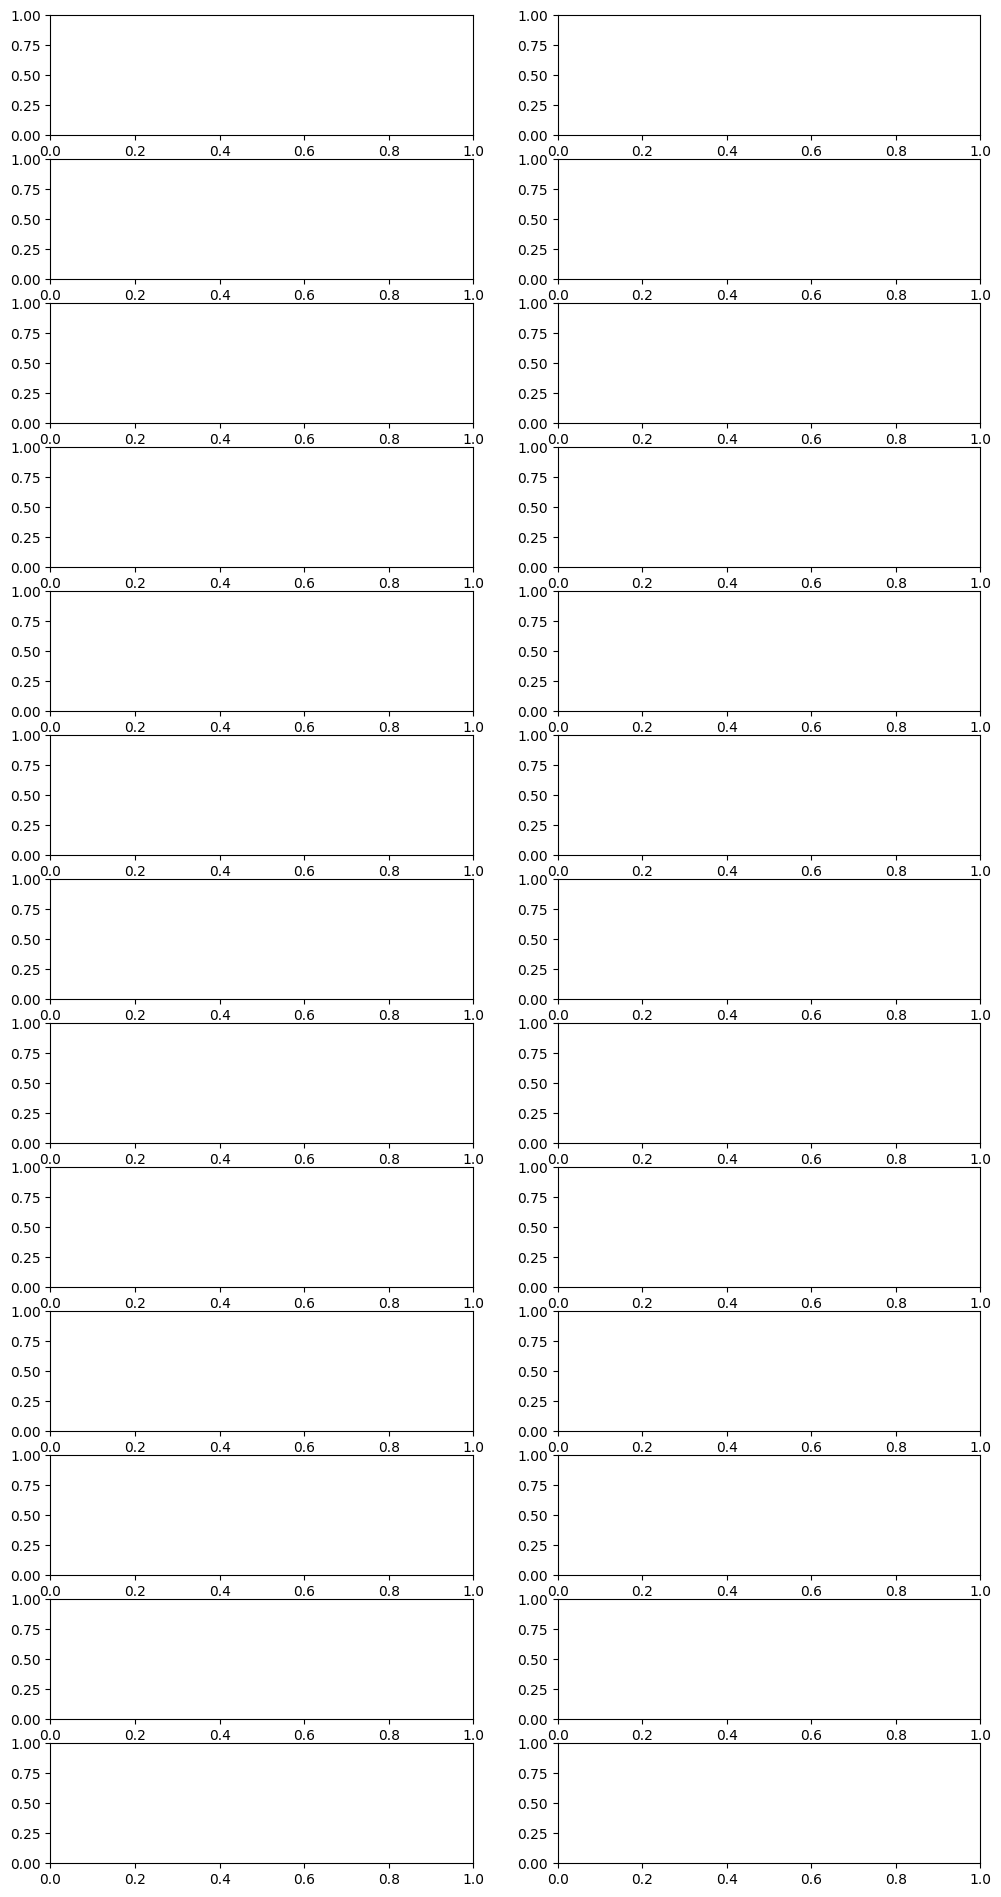

<Figure size 800x350 with 0 Axes>

In [48]:
fig, axes = plt.subplots(nrows=13, ncols=2, figsize=(12, 24))
axes = axes.flatten()

for idx, ax in enumerate(axes):
    if idx < len(explanations_list):
        exp = explanations_list[idx]
        title = titles_list[idx]
        
        # Create a temporary figure to render the beeswarm plot
        temp_fig = plt.figure()
        shap.plots.beeswarm(exp, show=False) # Generate plot
        
        # Get the image data
        buf = io.BytesIO()
        temp_fig.savefig(buf, format='png', dpi=100, bbox_inches='tight')
        buf.seek(0)
        temp_fig.clf() # Close temp figure
        temp_fig.close()
        
        # Display the image on the specific axis
        ax.imshow(plt.imread(buf)) # This might not work directly, better to use:
        # Actually, let's use the image from the buffer
        from PIL import Image
        import numpy as np
        img = Image.open(buf)
        ax.imshow(img)
        
        # Set title
        ax.set_title(title, fontsize=10)
        
        # Hide axis ticks
        ax.axis('off')
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()

shapeof shap_values (396, 5, 2)


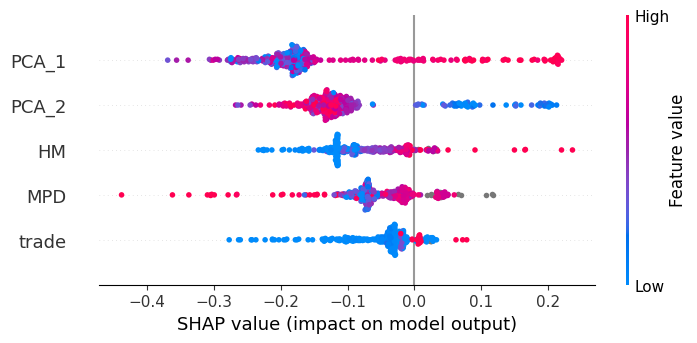

  model   roc_auc  accuracy  balanced_acc  f1_score  precision    recall  \
0    RF  0.998765  0.989899      0.994444  0.990137   0.990909  0.989899   

       time  TP  TN  FP  FN  
0  0.447014   9  89   1   0  
          0         1         2         3         4
0     PCA_1     PCA_2        HM     trade       MPD
1  0.175722  0.128493  0.081179  0.049584  0.064588
shapeof shap_values (7909, 5, 2)


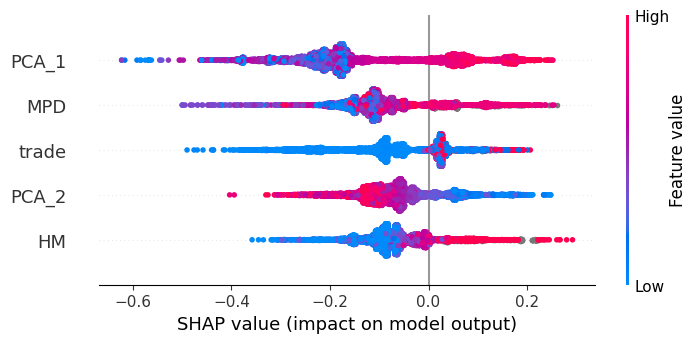

  model   roc_auc  accuracy  balanced_acc  f1_score  precision    recall  \
0    RF  0.996026  0.988878      0.958886  0.988793   0.988762  0.988878   

        time   TP    TN  FP  FN  
0  13.930015  166  1790   8  14  
          0         1         2         3         4
0     PCA_1     PCA_2        HM     trade       MPD
1  0.173448  0.089557  0.081298  0.098036  0.111531


In [13]:
a = pd.read_csv("//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables/AG_allv.csv")
variables = ["PCA_1", "PCA_2", "HM", "trade", "MPD"]

for S in ['S1', 'S2']:
    mask = ((a['S'] == S))
    x = a.loc[mask, variables]
    Y = a.loc[mask, 'Occurrence']

    z, b = features_ml_models(x, Y, 1, variables, is_binary=True,  is_balanced=False, plot=True)
    print(z)
    print(b)





original function from Ebi

In [6]:
# Configuration
txtfiles = []

for file in glob.glob("//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables/*_allv.csv"):
    txtfiles.append(file)
    
    
S_levels = ['S1', 'S2']
PA_N_levels = range(1, 11)  # 1 to 10

variables = ["PCA_1", "PCA_2", "HM", "trade", "MPD"]

XGGBoost with the 10 PA_sets (equal way technique): 14m for 10 replicates x Pa

In [ ]:
# Initialize storage
metrics_rows = []
shap_values_store = {}

replicates = 10

##initialize progress bar
max_count = 13*10*10*2

f = IntProgress(min=0, max=max_count) # instantiate the bar
display(f) # display the bar
count = 0

# Loop structure
for file in txtfiles:

    a = pd.read_csv(file)
    print(a.loc[1, 'Taxa'])
    sp_name = a.loc[1, 'Taxa']
    # Assuming you have a way to get the specific dataset for this taxa
    # dataset = get_species_dataset(taxa) 
    
    for s in S_levels:
        seed = 0 

        for pa_n in PA_N_levels:
            for rep in range(1, replicates + 1):
                print(f"species {sp_name} s {s} rep {seed}/100")
                # 1. Filter or Prepare the specific dataset slice
                mask = ((a['PA_N'] == pa_n ) & (a['S'] == s) ) | ((a['PA_N'].isna()) & (a['S'] == s))
                x = a.loc[mask, variables]
                Y = a.loc[mask, 'Occurrence']

                #print(f"X shape {x.shape}")
                #print(f"Y shape {Y.shape}")

                # 2. Run your function
                metrics_df, shap_df =  features_ml_models(x, Y, seed, variables, is_binary=True, is_balanced=True) 
                
                # MOCK DATA FOR DEMONSTRATION (Replace with your function call)
                #metrics_df = pd.DataFrame({'mean_score': [0.85], 'accuracy': [0.92]})
                #shap_df = pd.DataFrame(np.random.rand(20, 5), columns=['var_1', 'var_2', 'var_3', 'var_4', 'var_5'])
                
                # 3. Store Metrics
                # Add metadata columns
                metrics_df['Taxa'] = sp_name
                metrics_df['S'] = s
                metrics_df['PA_N'] = pa_n
                metrics_df['Replicate'] = rep
                
                metrics_rows.append(metrics_df)
                
                # 4. Store SHAP Values
                # Key: (Taxa, S, Replicate, PA_N) -> Value: (n, 5) DataFrame
                key = (sp_name, s, rep, pa_n)
                shap_values_store[key] = shap_df

                seed += 1

                while count <= max_count:
                    f.value += 1 # signal to increment the progress bar
                    time.sleep(.1)
                    count += 1

# 5. Combine all metrics into one DataFrame
final_metrics_df = pd.concat(metrics_rows, ignore_index=True)

final_metrics_df.to_csv("//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/XGboost/metrics_equal_w.csv")

In [ ]:

#create data frame from dictionary
classA = pd.DataFrame(
   shap_values_store_w
)

classA.head
#save dataframe to csv file
#classA.to_csv("student.csv", index=False)
#save dataframe to csv file
#classA.to_csv("//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/XGboost/shap_equal_w.csv", index=False)



: 

XGBoost with the whole dataset but with weight for presences (weight )

In [17]:
shap_values_store_w

{('Wasmannia auropunctata',
  'S1',
  1,
  'Weighted'):         PCA_1     PCA_2        HM     trade       MPD
 0    1.364863  1.928663  1.333734  1.177040  0.237624
 1    1.507247  1.790932  1.108542  1.507605 -1.160535
 2    1.122633  1.763612  1.262852  1.409952 -1.360785
 3    2.602176 -1.624048  1.460349  0.444805  1.773863
 4    1.466085  1.933892  1.333734  1.186372  0.121840
 ..        ...       ...       ...       ...       ...
 336 -1.595188 -3.170265 -1.124662 -1.087056 -1.057699
 337 -2.343429 -1.692297 -2.046457 -0.727371 -1.294838
 338 -1.832430 -3.436986 -1.057313 -1.003660 -0.121449
 339 -1.661822 -2.788067 -1.639284 -0.499121 -1.176049
 340 -2.334928 -1.638621 -2.046457 -0.727371 -1.119907
 
 [341 rows x 5 columns],
 ('Wasmannia auropunctata',
  'S2',
  1,
  'Weighted'):          PCA_1     PCA_2        HM     trade       MPD
 0     2.727919  1.359728  3.048892  0.744681 -0.766913
 1     3.484850  1.500931  0.543254  1.689609 -0.217332
 2     2.600704  0.740994 -0.490107

In [18]:
import pandas as pd

# Assuming your variable is 'results_dict'
# Structure: { ('Species', 'S', 'Replicate', 'Model'): DataFrame }

processed_dfs = []

for key, df in shap_values_store_w.items():
    # 1. Unpack the 4-element tuple key
    # key[0] = Species, key[1] = S, key[2] = Replicate, key[3] = Model
    species = key[0]
    s_val = key[1]
    replicate = key[2]
    model = key[3]
    
    # 2. Add metadata columns to the DataFrame
    # We create a new DataFrame with the metadata added
    df_with_meta = df.assign(
        Species=species,
        S=s_val,
        Replicate=replicate,
        Model=model
    )
    
    processed_dfs.append(df_with_meta)

# 3. Combine all DataFrames into one
if processed_dfs:
    final_df = pd.concat(processed_dfs, ignore_index=True)
    
    # Reorder columns to match your specific request
    # Ensure these columns exist before selecting
    cols = ['Species', 'S', 'Replicate', 'Model', 'PCA_1', 'PCA_2', 'HM', 'trade', 'MPD']
    available_cols = [c for c in cols if c in final_df.columns]
    
    final_df = final_df[available_cols]
    
    print("Final DataFrame Head:")
    print(final_df.head())
    print(f"Total rows: {len(final_df)}")
    print(f"Total species: {final_df['Species'].nunique()}")
else:
    print("No DataFrames found in the dictionary.")

Final DataFrame Head:
                  Species   S  Replicate     Model     PCA_1     PCA_2  \
0  Wasmannia auropunctata  S1          1  Weighted  1.364863  1.928663   
1  Wasmannia auropunctata  S1          1  Weighted  1.507247  1.790932   
2  Wasmannia auropunctata  S1          1  Weighted  1.122633  1.763612   
3  Wasmannia auropunctata  S1          1  Weighted  2.602176 -1.624048   
4  Wasmannia auropunctata  S1          1  Weighted  1.466085  1.933892   

         HM     trade       MPD  
0  1.333734  1.177040  0.237624  
1  1.108542  1.507605 -1.160535  
2  1.262852  1.409952 -1.360785  
3  1.460349  0.444805  1.773863  
4  1.333734  1.186372  0.121840  
Total rows: 167772
Total species: 13


In [ ]:
features_ml_models(x, Y, seed, variables, is_binary=True, is_balanced=True, plot = True) 

In [7]:
# --- Usage Example: Calculate Mean and SD for SHAP values ---

# Define the groups you want to aggregate (e.g., all replicates and PA_N for S1)
target_species = "Linepithema humile"
target_S = "S1"

# Extract all SHAP dataframes for this group
shap_groups = []
for s_val in S_levels:
    for pa_n_val in PA_N_levels:
        for rep_val in range(1, replicates + 1):
            key = (target_species, s_val, rep_val, pa_n_val)
            if key in shap_values_store:
                shap_groups.append(shap_values_store[key])

if shap_groups:
    # Concatenate all (n, 5) dataframes vertically
    combined_shap = pd.concat(shap_groups, ignore_index=False)
    
    # Calculate Mean and SD
    #shap_mean = combined_shap.mean()

    shap_mean =np.abs(combined_shap).mean(0)
    shap_std = combined_shap.std()
    
    print(f"SHAP Mean for {target_species} ({target_S}):")
    print(shap_mean)
    print(f"SHAP Std for {target_species} ({target_S}):")
    print(shap_std)

SHAP Mean for Linepithema humile (S1):
0    2.470854
1    0.782348
2    2.948035
3    1.549019
4    0.962254
dtype: float32
SHAP Std for Linepithema humile (S1):
0    3.002866
1    1.022028
2    3.380500
3    1.907282
4    1.183205
dtype: float32


In [10]:
txtfiles = []
for file in glob.glob("//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables/*_allv.csv"):
    txtfiles.append(file)

print(txtfiles)

['//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\WA_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\HE_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\AG_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\TA_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\LH_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\MF_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\PM_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\MP_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\HP_al

In [5]:
variables = ["PCA_1", "PCA_2", "HM", "trade", "MPD"]

- XGBoost better than RF in actual(1) predicted (0) but not from far in terms of numbers for S2, very equal rf and xgboost in S
- Shap values don't agree with the % of variabel importance, if they do usually in S2 (1 agree in S1, HO; 4 agree in S2)

In [ ]:
# 1m 30 to run ! 

for file in txtfiles:
    sp = pd.read_csv(file)

    sp.head
    print(sp.loc[1, 'Taxa'])
    for S in ['S1', 'S2']:
        mask = ((sp['S'] == S))
        x = sp.loc[mask, variables]
        Y = sp.loc[mask, 'Occurrence']

        z, b = features_ml_models(x, Y, 1, is_binary=True)
        print(z)
        print(b)


In [4]:
for S in ['S1', 'S2']:
    mask = ((a['S'] == S))
    x = a.loc[mask, variables]
    Y = a.loc[mask, 'Occurrence']

    z, b = features_ml_models(x, Y, 1, is_binary=True)
    print(z)
    print(b)


NameError: name 'variables' is not defined

Option 1. Equal sampling

In [ ]:
def applyXGB (a, PA_sep = False):

    #for non equal PA --> weight
    if PA_sep == False:
        CV_repeats = 100

        shap_values_per_cv = dict()
        for sample in CV_repeats:
            ## Create keys for each sample
            shap_values_per_cv[sample] = {} 
            ## Then, keys for each CV fold within each sample
            for CV_repeat in range(CV_repeats):
                shap_values_per_cv[sample][CV_repeat] = {}

        for S in ['S1', 'S2']:
            mask = ((a['S'] == S))
            x = a.loc[mask, variables]
            Y = a.loc[mask, 'Occurrence']

            b, c, d = features_ml_models(x, Y, 1, is_binary=True, is_balanced=False)
            print(b)
            print(c)
            print(d.shape)




    # for equal PA
    if PA_sep == True:
        CV_repeats = 10
        for S in ['S1', 'S2']:
            for pa_n in range(1,10):

                mask = ((a['PA_N'] == 1 ) & (a['S'] == S) ) | ((a['PA_N'].isna()) & (a['S'] == S))
                x = a.loc[mask, variables]
                Y = a.loc[mask, 'Occurrence']

                z, b = features_ml_models(x, Y, 1, is_binary=True, is_balanced=True)


In [ ]:
np.random.seed(1) # Reproducibility 


for file in txtfiles:
    sp = pd.read_csv(file)

    sp.head
    print(sp.loc[1, 'Taxa'])
    
    #option 1 : weighted
    applyXGB(sp, PA_sep = False)

    #option 2 : equal PA by set
    applyXGB(sp, PA_sep = True)



Option 2. Weighted

In [ ]:
# Filter the dictionary keys
keys_to_use = [
    k for k in shap_values_store.keys() 
    if k[0] == target_species and k[1] == target_S
]

# Retrieve and stack
all_shap = pd.concat([shap_values_store[k] for k in keys_to_use], ignore_index=True)

# Compute
mean_shap = all_shap.mean()
std_shap = all_shap.std()